In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import xgboost
print("Tout fonctionne, sklearn", sklearn.__version__)

Tout fonctionne, sklearn 1.6.1


# F3. Prévision de l'inflation

**Nom et prénom :** Raoufi Nouhaila    **Code Apogée :** 25007620    **Groupe :** FIN3    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/Nouhaila-25/25007620-nouhaila-raoufi-FIN3

## 1. Sujet et problématique
- **Intérêt du sujet** : L'inflation guide les décisions des banques centrales (taux directeur), des entreprises (prix, salaires) et des investisseurs (placements obligataires). Savoir si le chômage et le taux directeur aident à l'anticiper est utile pour ces décisions.
- **Problématique** : Le taux de chômage et le taux directeur permettent-ils de prévoir l'inflation américaine (variation annuelle de l'indice des prix) 12 mois à l'avance mieux qu'une simple règle naïve ?
- **Objectif mesurable** : Obtenir un RMSE inférieur d'au moins 10 % à celui de la règle « inflation dans 12 mois = inflation actuelle », sur les 60 derniers mois (jeu de test), avec un écart de 12 mois entre apprentissage et test.
- **Nature du problème** : Régression sur séries temporelles mensuelles, car la variable à prédire (le taux d'inflation) est numérique continue et les données sont ordonnées dans le temps.
- **Algorithme principal envisagé** : n°2, Ridge. Régression linéaire pénalisée, adaptée à peu de variables corrélées entre elles (retards successifs). Je n'ai pas retenu le gradient boosting (n°7) : environ 950 observations seulement, et les arbres n'extrapolent pas au-delà des valeurs vues à l'apprentissage.

In [2]:
!git clone https://github.com/Nouhaila-25/25007620-nouhaila-raoufi-FIN3.git

Cloning into '25007620-nouhaila-raoufi-FIN3'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 46 (delta 10), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 26.15 KiB | 2.90 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, sys

GRAINE = 42
np.random.seed(GRAINE)

RACINE = Path("25007620-nouhaila-raoufi-FIN3")
RAW = RACINE / "data" / "raw"

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print([str(p) for p in RAW.rglob("*") if p.is_file()])

Python 3.13.18 | pandas 2.2.3 | sklearn 1.6.1
['25007620-nouhaila-raoufi-FIN3/data/raw/FEDFUNDS.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/UNRATE.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/CPIAUCSL.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/.gitkeep']


assembler les données et vérifier leur qualité

In [6]:
series = {}
for f in RAW.glob("*.csv"):
    df = pd.read_csv(f)
    nom = df.columns[1]
    df.columns = ["date", nom]
    df["date"] = pd.to_datetime(df["date"])
    df[nom] = pd.to_numeric(df[nom], errors="coerce")
    series[nom] = df.set_index("date")
    print(f.name, "->", nom)

cpi = series["CPIAUCSL"]
chom = series["UNRATE"]
taux = series["FEDFUNDS"]

for nom, d in [("CPIAUCSL", cpi), ("UNRATE", chom), ("FEDFUNDS", taux)]:
    print(nom, d.shape, d.index.min().date(), "->", d.index.max().date(), "| manquants :", int(d.iloc[:, 0].isna().sum()))
    display(d.head(3))

FEDFUNDS.csv -> FEDFUNDS
UNRATE.csv -> UNRATE
CPIAUCSL.csv -> CPIAUCSL
CPIAUCSL (958, 1) 1947-01-01 -> 2026-10-01 | manquants : 1


,CPIAUCSL
date,
1947-01-01,21.48
1947-02-01,21.62
1947-03-01,22.00


UNRATE (946, 1) 1948-01-01 -> 2026-10-01 | manquants : 1


,UNRATE
date,
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0


FEDFUNDS (868, 1) 1954-07-01 -> 2026-10-01 | manquants : 0


,FEDFUNDS
date,
1954-07-01,0.80
1954-08-01,1.22
1954-09-01,1.07


**Étape 3 (0:25 à 0:50) : exploration et préparation**

In [7]:
df = cpi.join(chom, how="inner").join(taux, how="inner")
df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100   # variation annuelle en %

print(df.shape, df.index.min().date(), "->", df.index.max().date(), "| fréquence :", pd.infer_freq(df.index))
print("Doublons de dates :", df.index.duplicated().sum(), "| dates triées :", df.index.is_monotonic_increasing)
print(df.isna().sum())
display(df.describe().round(2))

(868, 4) 1954-07-01 -> 2026-10-01 | fréquence : MS
Doublons de dates : 0 | dates triées : True
CPIAUCSL      1
UNRATE        1
FEDFUNDS      0
inflation    12
dtype: int64


/tmp/ipykernel_6811/1482388109.py:2: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100   # variation annuelle en %


,CPIAUCSL,UNRATE,FEDFUNDS,inflation
count,867.00,867.00,868.00,856.00
mean,136.52,5.79,4.59,3.62
std,89.55,1.67,3.52,2.74
min,26.71,3.40,0.05,-1.96
25%,41.85,4.40,1.94,1.76
50%,131.60,5.50,4.24,2.96
75%,213.09,6.85,6.10,4.39
max,337.48,14.80,19.10,14.59


trois graphiques

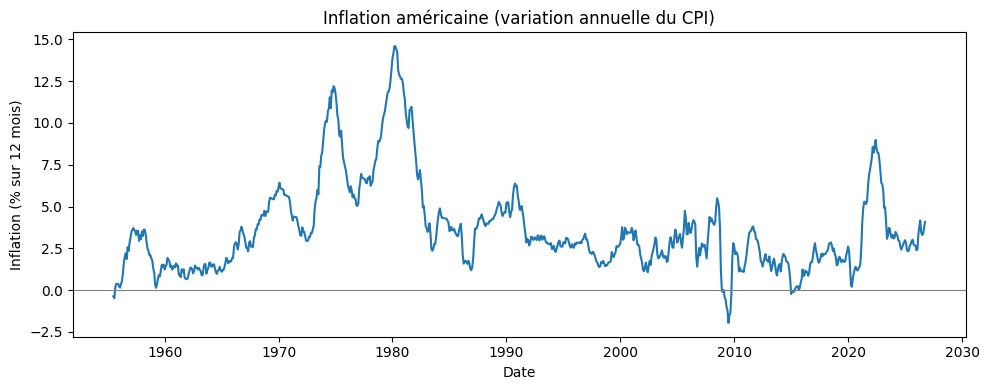

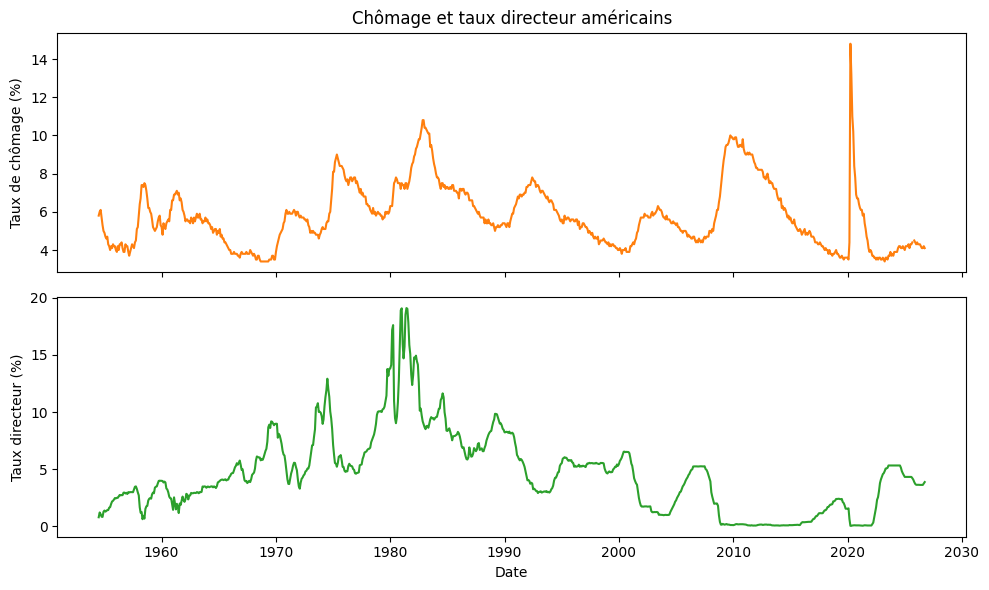

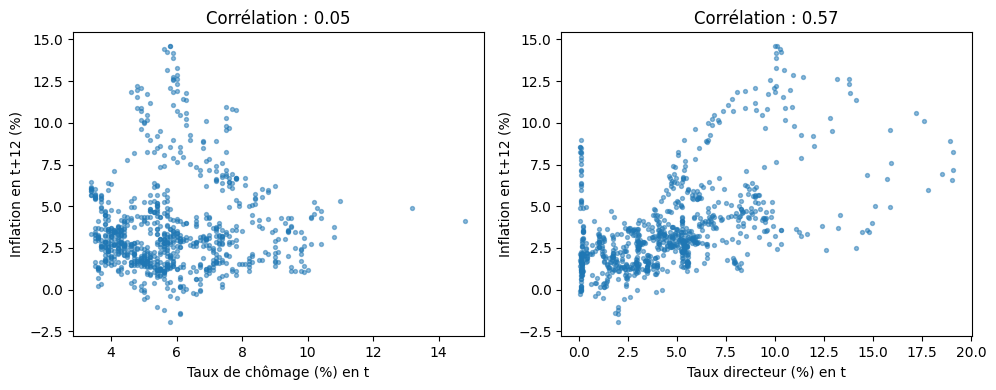

In [8]:
(RACINE / "figures").mkdir(exist_ok=True)

# Graphique 1 : inflation
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df["inflation"])
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Inflation américaine (variation annuelle du CPI)")
ax.set_xlabel("Date"); ax.set_ylabel("Inflation (% sur 12 mois)")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g1_inflation.png", dpi=150); plt.show()

# Graphique 2 : chômage et taux directeur
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(df.index, df["UNRATE"], color="tab:orange")
axes[0].set_ylabel("Taux de chômage (%)")
axes[1].plot(df.index, df["FEDFUNDS"], color="tab:green")
axes[1].set_ylabel("Taux directeur (%)"); axes[1].set_xlabel("Date")
axes[0].set_title("Chômage et taux directeur américains")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g2_chomage_taux.png", dpi=150); plt.show()

# Graphique 3 : variables d'aujourd'hui contre inflation dans 12 mois
futur = df["inflation"].shift(-12)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, v, lab in zip(axes, ["UNRATE", "FEDFUNDS"], ["Taux de chômage (%)", "Taux directeur (%)"]):
    ok = futur.notna() & df[v].notna()
    ax.scatter(df.loc[ok, v], futur[ok], s=8, alpha=0.5)
    ax.set_xlabel(lab + " en t"); ax.set_ylabel("Inflation en t+12 (%)")
    ax.set_title(f"Corrélation : {df.loc[ok, v].corr(futur[ok]):.2f}")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g3_relations.png", dpi=150); plt.show()

construire variables et cible, sans fuite

In [9]:
variables = ["inflation", "UNRATE", "FEDFUNDS"]
X = pd.DataFrame(index=df.index)
for v in variables:
    for k in [0, 3, 6, 12]:
        X[f"{v}_t-{k}"] = df[v].shift(k)            # shift positif = passé seulement

y = df["inflation"].shift(-12).rename("inflation_t+12")   # cible : inflation dans 12 mois

data = pd.concat([X, y], axis=1).dropna()
X, y = data.drop(columns="inflation_t+12"), data["inflation_t+12"]

# Preuve d'alignement
d = data.index[10]
print("Date t :", d.date())
print("Inflation réelle 12 mois plus tard :", round(df.loc[d + pd.DateOffset(months=12), "inflation"], 4))
print("Cible dans le tableau              :", round(data.loc[d, "inflation_t+12"], 4))
display(data[["inflation_t-0", "UNRATE_t-0", "FEDFUNDS_t-0", "inflation_t+12"]].head(3))
print(X.shape)

Date t : 1957-05-01
Inflation réelle 12 mois plus tard : 3.3571
Cible dans le tableau              : 3.3571


,inflation_t-0,UNRATE_t-0,FEDFUNDS_t-0,inflation_t+12
date,,,,
1956-07-01,1.980568,4.4,2.75,3.297911
1956-08-01,2.208084,4.1,2.73,3.551813
1956-09-01,1.862197,3.9,2.95,3.546618


(831, 12)


découpage chronologique

In [10]:
N_TEST, GAP = 60, 12
i_test = len(data) - N_TEST
i_fin_train = i_test - GAP

X_train, y_train = X.iloc[:i_fin_train], y.iloc[:i_fin_train]
X_test, y_test = X.iloc[i_test:], y.iloc[i_test:]

print("Apprentissage :", X_train.index.min().date(), "->", X_train.index.max().date(), f"({len(X_train)} mois)")
print("Écart ignoré  :", X.index[i_fin_train].date(), "->", X.index[i_test - 1].date(), f"({GAP} mois)")
print("Test          :", X_test.index.min().date(), "->", X_test.index.max().date(), f"({len(X_test)} mois)")

Apprentissage : 1956-07-01 -> 2019-09-01 (759 mois)
Écart ignoré  : 2019-10-01 -> 2020-09-01 (12 mois)
Test          : 2020-10-01 -> 2025-09-01 (60 mois)


« Préparation »

les variables créées et leurs formules (inflation = variation sur 12 mois du CPI ; retards 0, 3, 6, 12 mois ; cible = inflation à t+12) ;

la prévention des fuites : retards avec shift positif, cible décalée vers le futur, lignes incomplètes retirées, écart de 12 mois entre apprentissage et test parce que la cible porte sur 12 mois, pas de mélange aléatoire ;

la standardisation : nécessaire pour Ridge (la pénalité dépend de l’échelle des variables), faite dans un Pipeline, donc ajustée sur l’apprentissage seulement.

**Étape 4 (0:50 à 1:25) : algorithme, évaluation, résultats**

## 5. Algorithme : Ridge (n°2)
**Principe.** Ridge est une régression linéaire à laquelle on ajoute une pénalité sur la taille des coefficients, pour éviter qu'ils deviennent trop grands quand les variables sont corrélées entre elles (ici, les retards d'une même série).
**Formule.** On cherche w et b qui minimisent : Σ (yᵢ − w·xᵢ − b)² + α‖w‖²
- yᵢ : inflation dans 12 mois (cible) pour le mois i
- xᵢ : vecteur des variables du mois i (12 variables)
- w : coefficients appris ; b : constante apprise
- α : hyperparamètre de pénalité, fixé par validation ; ‖w‖² : somme des carrés des coefficients
**Appris / fixés.** Appris : w et b. Fixé par validation : α.
**Hyperparamètres.** α grand : coefficients écrasés vers 0, modèle trop simple (sous-apprentissage). α petit : proche de la régression linéaire, risque de surapprentissage. Aussi : standardisation des variables avant ajustement.
**Pourquoi Ridge et pas le gradient boosting.** ... (environ 950 observations, relations supposées proches du linéaire, besoin d'interpréter les coefficients, les arbres n'extrapolent pas hors des valeurs vues à l'apprentissage).

référence naïve, validation croisée, réglage

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

tscv = TimeSeriesSplit(n_splits=5, gap=12)
pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
grille = {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}   # 5 configurations essayées

gs = GridSearchCV(pipe, grille, cv=tscv, scoring="neg_root_mean_squared_error", return_train_score=True)
gs.fit(X_train, y_train)

res = pd.DataFrame(gs.cv_results_)
b = gs.best_index_
rmse_val_ridge = -res.loc[b, "mean_test_score"]
std_val_ridge = res.loc[b, "std_test_score"]

# Référence naïve en validation : inflation dans 12 mois = inflation actuelle
rm_naif = [rmse(y_train.iloc[v], X_train["inflation_t-0"].iloc[v]) for _, v in tscv.split(X_train)]

print("Meilleur alpha :", gs.best_params_)
print(f"RMSE validation Ridge : {rmse_val_ridge:.3f} (± {std_val_ridge:.3f})")
print(f"RMSE validation naïve : {np.mean(rm_naif):.3f} (± {np.std(rm_naif):.3f})")

Meilleur alpha : {'ridge__alpha': 100}
RMSE validation Ridge : 2.763 (± 1.622)
RMSE validation naïve : 1.925 (± 0.669)


courbe de validation (surapprentissage)

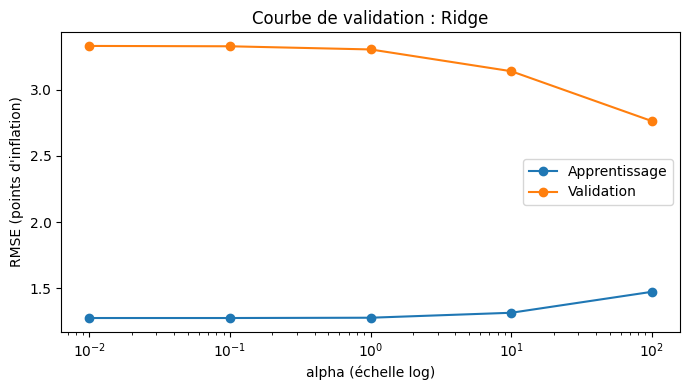

In [12]:
alphas = res["param_ridge__alpha"].astype(float)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(alphas, -res["mean_train_score"], "o-", label="Apprentissage")
ax.semilogx(alphas, -res["mean_test_score"], "o-", label="Validation")
ax.set_xlabel("alpha (échelle log)"); ax.set_ylabel("RMSE (points d'inflation)")
ax.set_title("Courbe de validation : Ridge"); ax.legend()
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g4_validation.png", dpi=150); plt.show()

résultat sur le test, utilisé une seule fois

In [13]:
pred = gs.predict(X_test)
naif = X_test["inflation_t-0"]

tab = pd.DataFrame({
    "RMSE validation": [np.mean(rm_naif), rmse_val_ridge],
    "RMSE test": [rmse(y_test, naif), rmse(y_test, pred)],
    "MAE test": [mean_absolute_error(y_test, naif), mean_absolute_error(y_test, pred)],
}, index=["Référence naïve", "Ridge"]).round(3)
display(tab)

gain = 1 - rmse(y_test, pred) / rmse(y_test, naif)
print(f"Gain de RMSE de Ridge contre la référence : {gain*100:.1f} %  (objectif : au moins 10 %)")
print("Objectif atteint :", gain >= 0.10)
print(f"RMSE apprentissage : {rmse(y_train, gs.predict(X_train)):.3f} | RMSE test : {rmse(y_test, pred):.3f}")

,RMSE validation,RMSE test,MAE test
Référence naïve,1.925,2.931,2.189
Ridge,2.763,2.896,2.255


Gain de RMSE de Ridge contre la référence : 1.2 %  (objectif : au moins 10 %)
Objectif atteint : False
RMSE apprentissage : 1.694 | RMSE test : 2.896


graphique prévision contre réel et erreurs

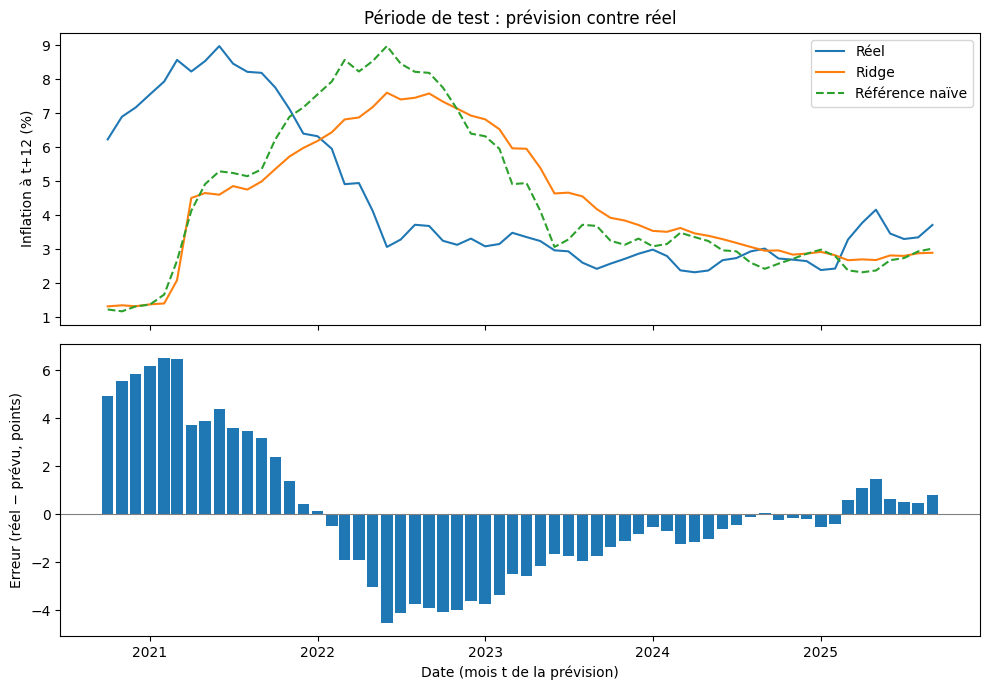

,réel,prévu,erreur absolue
date,,,
2021-02-01,7.94,1.41,6.53
2021-03-01,8.57,2.09,6.48
2021-01-01,7.56,1.38,6.18
2020-12-01,7.17,1.33,5.85
2020-11-01,6.90,1.35,5.55


In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(y_test.index, y_test, label="Réel")
axes[0].plot(y_test.index, pred, label="Ridge")
axes[0].plot(y_test.index, naif, label="Référence naïve", linestyle="--")
axes[0].set_ylabel("Inflation à t+12 (%)"); axes[0].legend()
axes[0].set_title("Période de test : prévision contre réel")
axes[1].bar(y_test.index, y_test - pred, width=25)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_ylabel("Erreur (réel − prévu, points)"); axes[1].set_xlabel("Date (mois t de la prévision)")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g5_test.png", dpi=150); plt.show()

err = (y_test - pred).abs().sort_values(ascending=False).head(5)
display(pd.DataFrame({"réel": y_test[err.index], "prévu": pred[[y_test.index.get_loc(i) for i in err.index]], "erreur absolue": err}).round(2))

variables, stabilité, usage sur des cas non vus

In [15]:
# Coefficients (variables standardisées, donc comparables entre elles)
coefs = pd.Series(gs.best_estimator_["ridge"].coef_, index=X.columns).sort_values(key=abs, ascending=False)
display(coefs.round(3))

# Stabilité sur deux sous-périodes du test
for nom, sl in [("1re moitié du test", slice(0, 30)), ("2e moitié du test", slice(30, 60))]:
    print(f"{nom} : RMSE Ridge {rmse(y_test.iloc[sl], pred[sl]):.3f} | RMSE naïve {rmse(y_test.iloc[sl], naif.iloc[sl]):.3f}")

# Illustration sur 5 observations du test
idx = [5, 18, 30, 42, 55]
illus = pd.DataFrame({
    "inflation actuelle": X_test["inflation_t-0"].iloc[idx],
    "chômage": X_test["UNRATE_t-0"].iloc[idx],
    "taux directeur": X_test["FEDFUNDS_t-0"].iloc[idx],
    "prévu t+12": pred[idx],
    "réel t+12": y_test.iloc[idx],
}).round(2)
illus["erreur"] = (illus["réel t+12"] - illus["prévu t+12"]).round(2)
display(illus)

,0
inflation_t-0,1.100
FEDFUNDS_t-0,0.722
inflation_t-3,0.546
FEDFUNDS_t-12,-0.486
UNRATE_t-0,-0.438
UNRATE_t-12,0.281
inflation_t-6,0.245
FEDFUNDS_t-6,-0.172
UNRATE_t-6,0.117
FEDFUNDS_t-3,0.072


1re moitié du test : RMSE Ridge 3.933 | RMSE naïve 4.067
2e moitié du test : RMSE Ridge 1.140 | RMSE naïve 0.799


,inflation actuelle,chômage,taux directeur,prévu t+12,réel t+12,erreur
date,,,,,,
2021-03-01,2.67,6.1,0.07,2.09,8.57,6.48
2022-04-01,8.23,3.7,0.33,6.88,4.95,-1.93
2023-04-01,4.95,3.4,4.83,5.96,3.36,-2.60
2024-04-01,3.36,3.9,5.33,3.47,2.33,-1.14
2025-05-01,2.38,4.3,4.33,2.68,4.17,1.49


Section 6 « Protocole » : dates des 3 périodes, référence naïve (inflation actuelle), validation croisée chronologique à 5 plis avec écart de 12 mois, 5 valeurs d’alpha essayées, test utilisé une fois, RMSE principale (en points d’inflation, pénalise les grosses erreurs) et MAE secondaire.
Section 7 « Résultats » : tableau, écart entre apprentissage et test (surapprentissage ?), courbe de validation, où le modèle se trompe le plus (quelles périodes ? probablement 2021-2022 si elles sont dans ton test), coefficients sans parler de causalité, stabilité sur les deux moitiés, les 5 exemples.

**Étape 5 (1:25 à 1:40) : compte rendu**

8. Analyse critique : séries révisées après publication (biais d’anticipation), délai de publication ignoré, un seul découpage de test, 60 mois peu nombreux, changements de régime (période 2021-2022), seulement 3 variables. Piste concrète : utiliser les versions publiées à l’époque (archive ALFRED).
9. Conclusion : réponds en 3 à 5 lignes à ta problématique et à l’objectif chiffré (atteint ou non). Un résultat négatif honnête et bien expliqué est accepté.
10. Références : les 3 liens FRED, le lien du dépôt, comment reproduire (cloner le dépôt, installer requirements.txt, tout exécuter).

In [18]:
import matplotlib, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nmatplotlib=={matplotlib.__version__}\nscikit-learn=={sklearn.__version__}")

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
scikit-learn==1.6.1


*Déclaration des ressources et outils d’IA*

| Outil | Date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Claude (Anthropic) | 17/11/2026 | Suggestions de code et d'organisation du notebook ; explication des étapes | Sections 2 à 7 | Code lu, exécuté et adapté ; résultats vérifiés dans les sorties |